# Sales Data Analysis

## Project Overview

This project analyzes financial transaction data using Python and Pandas to identify sales trends, top-performing products, customer spending patterns, payment method preferences, and transaction status distributions.

## Objectives
- Clean and validate transaction data.
- Analyze revenue and transaction patterns.
- Identify top products and customers by revenue.
- Compare payment methods and transaction statuses.
- Explore monthly and yearly sales trends using valid dates.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [411]:
#Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load and Inspect Data

In [412]:
#Load Data
data = pd.read_csv("dirty_financial_transactions.csv")
data.head()

,Transaction_ID,Transaction_Date,Customer_ID,Product_Name,Quantity,Price,Payment_Method,Transaction_Status
0,T0001,2024-08-02,C2205,Headphones,-5.0,$420.21,pay pal,NaN
1,T0002,2020-02-10,C3156,Coffee,469.0,-445.34202525395585,creditcard,Pending
2,T0003,2025-02-30,C2919,Tablet,-4.0,810.9930123946459,credit card,completed
3,T0004,2020-08-17,C3009,Tab,-7.0,868.6083413217348,PayPal,Pending
4,T0005,2025-02-30,C3488,Coffee Machine,-10.0,-763.1224490039416,PayPal,completed


### Initial Data Check

In [413]:
#Check Rows and Columns
data.shape

(100000, 8)

In [414]:
#Dataset Overview: Shape , Column Types and Non Null Counts
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Transaction_ID      94982 non-null   object 
 1   Transaction_Date    95120 non-null   object 
 2   Customer_ID         95122 non-null   object 
 3   Product_Name        100000 non-null  object 
 4   Quantity            94981 non-null   float64
 5   Price               66503 non-null   object 
 6   Payment_Method      100000 non-null  object 
 7   Transaction_Status  83321 non-null   object 
dtypes: float64(1), object(7)
memory usage: 6.1+ MB


In [415]:
#check the all missing Values
data.isna().sum()

Transaction_ID         5018
Transaction_Date       4880
Customer_ID            4878
Product_Name              0
Quantity               5019
Price                 33497
Payment_Method            0
Transaction_Status    16679
dtype: int64

## Data Cleaning

In [416]:
#drop all the duplicated rows
data = data.drop_duplicates()

In [417]:
#check the price column there is any -ve values 
data["Price"].head(20)

0                 $420.21
1     -445.34202525395585
2       810.9930123946459
3       868.6083413217348
4      -763.1224490039416
5                     NaN
6                     NaN
7      -86.92126929493884
8      461.70198437439694
9       404.8907066405689
10     -600.8393093751704
11                    NaN
12                    NaN
13      905.5147299335418
14      523.8427581553709
15                    NaN
16     -94.55726526729006
17    -108.43782406112234
18                    NaN
19                    NaN
Name: Price, dtype: object

### Price

In [418]:
# Check negative values and count them (handles both "-5.0" and "$-5.0")
(data["Price"].astype(str).str.startswith("-")).sum()

np.int64(29662)

In [419]:
# Count of prices with a "$" sign 
data["Price"].astype(str).str.startswith("$").sum()

np.int64(6575)

In [420]:
# Remove the "$" sign from Price values
data.Price = data.Price.str.replace("$", "", regex=False)

In [421]:
data["Price"].head(10)

0                 420.21
1    -445.34202525395585
2      810.9930123946459
3      868.6083413217348
4     -763.1224490039416
5                    NaN
6                    NaN
7     -86.92126929493884
8     461.70198437439694
9      404.8907066405689
Name: Price, dtype: object

In [422]:
# Convert Price from text to float
data.Price = data.Price.astype(float)

In [423]:
#check the Price type
data["Price"].dtype

dtype('float64')

In [424]:
# Count negative values in Price
(data["Price"] < 0).sum()

np.int64(32876)

In [425]:
# Replace negative Price values with NaN
data.loc[data["Price"] < 0, "Price"] = np.nan

In [426]:
(data["Price"] < 0).sum()

np.int64(0)

In [427]:
# Count non-missing values in Price
data["Price"].notna().sum()

np.int64(32999)

In [428]:
# Fill missing Price values with the median
data.Price = data.Price.fillna(data.Price.median())

In [429]:
#check the missing values in Price Column
data.Price.isna().sum()

np.int64(0)

### Quantity

In [430]:
# Show rows where Quantity is negative
data[data["Quantity"] < 0]

,Transaction_ID,Transaction_Date,Customer_ID,Product_Name,Quantity,Price,Payment_Method,Transaction_Status
0,T0001,2024-08-02,C2205,Headphones,-5.0,420.210000,pay pal,NaN
2,T0003,2025-02-30,C2919,Tablet,-4.0,810.993012,credit card,completed
3,T0004,2020-08-17,C3009,Tab,-7.0,868.608341,PayPal,Pending
4,T0005,2025-02-30,C3488,Coffee Machine,-10.0,523.847104,PayPal,completed
9,T0010,2025-02-30,C2846,Laptop,-1.0,404.890707,creditcard,Pending
...,...,...,...,...,...,...,...,...
99983,T99984,2025-02-30,C1089,Smartphone,-1.0,523.847104,pay pal,Failed
99985,T99986,2025-02-30,C227,Smartphone,-1.0,860.361141,creditcard,Pending
99987,T99988,2025-02-30,C3220,Coffee Machine,-6.0,871.220000,Cash,Pending
99995,NaN,2021-10-06,C1743,Headphones,-8.0,240.003238,PayPal,complete


In [431]:
# Count negative values in Quantity
(data.Quantity < 0).sum()

np.int64(31310)

In [432]:
# Replace negative Quantity values with NaN
data.loc[data.Quantity < 0 , "Quantity"] = np.nan

In [433]:
# Fill missing Quantity values with the median
data.Quantity = data.Quantity.fillna(data.Quantity.median())

In [434]:
# Count missing values in Quantity
data.Quantity.isna().sum()

np.int64(0)

### Transaction_Date

In [435]:
# Count missing values in Transaction_Date
data.Transaction_Date.isna().sum()

np.int64(4821)

In [436]:
# Show unique values in Transaction_Date
data.Transaction_Date.unique()

array(['2024-08-02', '2020-02-10', '2025-02-30', ..., '2020-09-01',
       '2023-05-31', '2023-09-13'], dtype=object)

In [437]:
#check Transaction_Date type
data["Transaction_Date"].dtype

dtype('O')

In [438]:
# Convert Transaction_Date to datetime; invalid dates become NaT
data.Transaction_Date = pd.to_datetime(data.Transaction_Date, errors="coerce")

In [439]:
#Again chcek the Transaction_Date 
data["Transaction_Date"].dtype

dtype('<M8[ns]')

In [440]:
# Count valid (non-missing) dates
data.Transaction_Date.notna().sum()

np.int64(31440)

In [441]:
#Again check the all mising values
data.isna().sum()

Transaction_ID         4966
Transaction_Date      67566
Customer_ID            4830
Product_Name              0
Quantity                  0
Price                     0
Payment_Method            0
Transaction_Status    16521
dtype: int64

In [442]:
#Again there is some duplicated values so drop it
data = data.drop_duplicates()

### Transaction_ID

In [443]:
# Drop rows with a missing Transaction_ID
data = data.dropna(subset="Transaction_ID")

### Customer_ID

In [444]:
# Show unique values in Customer_ID
data.Customer_ID.unique()

array(['C2205', 'C3156', 'C2919', ..., 'C1044', 'C1384', 'C4558'],
      dtype=object)

In [445]:
# Drop rows with a missing Customer_ID
data = data.dropna(subset=["Customer_ID"])

### Transaction_Status

In [446]:
# Show unique values in Transaction_Status
data.Transaction_Status.unique()

array([nan, 'Pending', 'completed', 'Completed', 'complete', 'Failed'],
      dtype=object)

In [447]:
# Standardize "complete" and "completed" to "Completed"
data.Transaction_Status = data.Transaction_Status.str.replace("completed", "Completed").str.replace("complete", "Completed")

In [448]:
# Show counts of each Transaction_Status, including missing values
print(data["Transaction_Status"].value_counts(dropna=False))

Transaction_Status
Completed    44637
Failed       14993
Pending      14932
NaN          14880
Name: count, dtype: int64


In [449]:
# Fill the NaN values by Unknown
data["Transaction_Status"] = data["Transaction_Status"].fillna("Unknown")
print(data["Transaction_Status"].value_counts())

Transaction_Status
Completed    44637
Failed       14993
Pending      14932
Unknown      14880
Name: count, dtype: int64


In [450]:
# Keep only rows with a known transaction status
known = data[data["Transaction_Status"] != "Unknown"]
# Show the percentage share of each status among known rows
print(known["Transaction_Status"].value_counts(normalize=True) * 100)

Transaction_Status
Completed    59.865615
Failed       20.108098
Pending      20.026287
Name: proportion, dtype: float64


In [451]:
#Chcek there is still missing values or not
data.isna().sum()

Transaction_ID            0
Transaction_Date      61032
Customer_ID               0
Product_Name              0
Quantity                  0
Price                     0
Payment_Method            0
Transaction_Status        0
dtype: int64

### Payment_Method

In [452]:
# Standardize Payment_Method spellings PayPal, Credit Card
data.Payment_Method = (data.Payment_Method.str.replace("pay pal", "PayPal").str.replace("creditcard", "Credit Card")
                       .str.replace("credit card", "Credit Card").str.replace("PayPal ", "PayPal"))

In [453]:
# Show counts of each Payment_Method
data.Payment_Method.value_counts()

Payment_Method
Credit Card    38547
PayPal         38202
Cash           12693
Name: count, dtype: int64

### Product_Name

In [454]:
# Show unique values in Product_Name
data.Product_Name.unique()

array(['Headphones', 'Coffee ', 'Tablet', 'Tab', 'Coffee Machine',
       'Smartphone', 'Laptop', 'Coffee Ma', 'Cof', 'Smar', 'Coffee M',
       'T', 'Smartp', 'Headp', 'Smart', 'La', 'Lapt', 'Tabl', 'L', 'C',
       'Smartph', 'Hea', 'Head', 'Lapto', 'Headphon', 'Table',
       'Headphone', 'Coffee Mac', 'Sm', 'Coffee', 'Headph', 'S',
       'Coffee Mach', 'Smartphon', 'Headpho', 'Coffee Machin', 'Coff',
       'Smartpho', 'Co', 'Lap', 'H', 'Ta', 'Coffee Machi', 'He', 'Coffe',
       'Sma'], dtype=object)

In [455]:
# Map truncated product names (e.g. "Tabl") to the full product name
products = ["Laptop", "Tablet", "Smartphone", "Headphones", "Coffee Machine"]
def fix_product(x):
    x = str(x).strip()
    for p in products:
        if p.lower().startswith(x.lower()):
            return p
    return np.nan
data["Product_Name"] = data["Product_Name"].apply(fix_product)      

In [456]:
# Show counts of each Product_Name
print(data["Product_Name"].value_counts())

Product_Name
Tablet            18031
Smartphone        17960
Laptop            17846
Headphones        17821
Coffee Machine    17784
Name: count, dtype: int64


### Final Check After Cleaning

In [457]:
# Final check after cleaning
# Number of rows and columns
print(data.shape)
# Count of missing values per column
print(data.isna().sum())
# Data type of each column
print(data.dtypes)
# Summary statistics for Price and Quantity
print(data[["Price", "Quantity"]].describe())
# Confirm every Transaction_ID is unique
print(data["Transaction_ID"].is_unique)

(89442, 8)
Transaction_ID            0
Transaction_Date      61032
Customer_ID               0
Product_Name              0
Quantity                  0
Price                     0
Payment_Method            0
Transaction_Status        0
dtype: int64
Transaction_ID                object
Transaction_Date      datetime64[ns]
Customer_ID                   object
Product_Name                  object
Quantity                     float64
Price                        float64
Payment_Method                object
Transaction_Status            object
dtype: object
              Price      Quantity
count  89442.000000  89442.000000
mean     524.110300    215.378301
std      157.602088    273.914106
min       50.028806      1.000000
25%      523.847104      8.000000
50%      523.847104    106.000000
75%      523.847104    292.000000
max      999.987698   1000.000000
True


## Feature Engineering

In [458]:
# Mark rows whose Price was filled with the median
data["Price_Imputed"] = data["Price"] == data["Price"].median()

In [459]:
# Calculate revenue for each row (Price x Quantity)
data["Revenue"] = data["Price"] * data["Quantity"]

## Analysis

<Axes: title={'center': 'Revenue by Product'}, xlabel='Product_Name'>

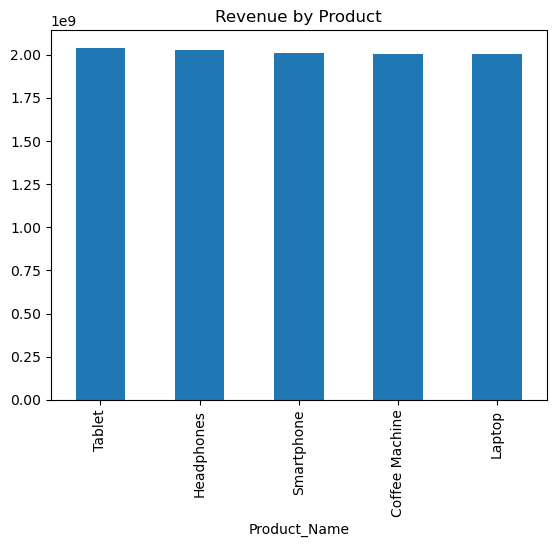

In [460]:
# Total revenue per product, highest first
revenue = data.groupby("Product_Name")["Revenue"].sum().sort_values(ascending=False)
revenue.plot(kind="bar", title="Revenue by Product")

#### How many total transactions are in the dataset?

In [461]:
len(data)

89442

**Finding:** The cleaned dataset contains 89,442 transactions, down from 100,000 in the raw data after removing duplicates and rows with missing or repeated Transaction_IDs.

#### What is the total revenue generated from all transactions?

In [462]:
print(f"{data['Revenue'].sum():,.2f}")
total_revenue = data.Revenue.sum()
total_revenue

10,085,173,222.97


np.float64(10085173222.966803)

**Finding:** Total revenue across all transactions is about 10.09 billion. Note that a large share of prices were filled with the median, so this total is partly an estimate.

#### What is the average revenue per transaction?

In [463]:
total_revenue / data.shape[0]

np.float64(112756.57099535792)

**Finding:** The average revenue per transaction is about 112,757.

#### Which product has the highest number of transactions?

In [464]:
data.Product_Name.value_counts()

Product_Name
Tablet            18031
Smartphone        17960
Laptop            17846
Headphones        17821
Coffee Machine    17784
Name: count, dtype: int64

**Finding:** Tablet has the most transactions (18,031), followed closely by Smartphone (17,960). Coffee Machine has the fewest (17,784). The gap between the highest and lowest is only about 250 transactions (roughly 1.4%), so sales volume is spread almost evenly across all five products.

#### Which product generates the highest total revenue?

In [465]:
data.groupby("Product_Name")["Revenue"].sum().sort_values(ascending= False)

Product_Name
Tablet            2.039419e+09
Headphones        2.026395e+09
Smartphone        2.012020e+09
Coffee Machine    2.004040e+09
Laptop            2.003300e+09
Name: Revenue, dtype: float64

**Finding:** Tablet generates the highest total revenue (about 2.04 billion), followed by Headphones (2.03 billion). Laptop is lowest (2.00 billion). The gap between the highest and lowest is under 2%, so revenue is spread almost evenly across all five products.

#### Which payment method is used most frequently?

In [466]:
data.Payment_Method.value_counts()

Payment_Method
Credit Card    38547
PayPal         38202
Cash           12693
Name: count, dtype: int64

**Finding:** Credit Card is the most used payment method (38,547 transactions, 43.1%), but PayPal is almost equal (38,202, 42.7%). Cash is far less common (12,693, 14.2%). Digital payments together account for about 86% of transactions.

#### What is the distribution of transaction statuses?

In [467]:
data.Transaction_Status.value_counts()

Transaction_Status
Completed    44637
Failed       14993
Pending      14932
Unknown      14880
Name: count, dtype: int64

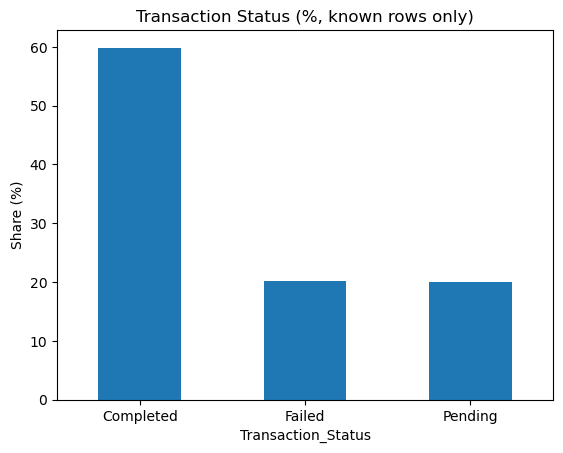

In [468]:
# Transaction status among known rows (%)
(known["Transaction_Status"].value_counts(normalize=True) * 100).plot(kind="bar", title="Transaction Status (%, known rows only)")
plt.ylabel("Share (%)")
plt.xticks(rotation=0)
plt.show()

**Finding:** Among transactions with a known status (74,562 rows), about 59.9% were completed, 20.1% failed and 20.0% were pending. The failed rate is therefore about 20%, roughly one in five transactions. Another 14,880 transactions (16.6% of all rows) have an unknown status and were excluded from these percentages.

#### Which product generates the highest average revenue per transaction?

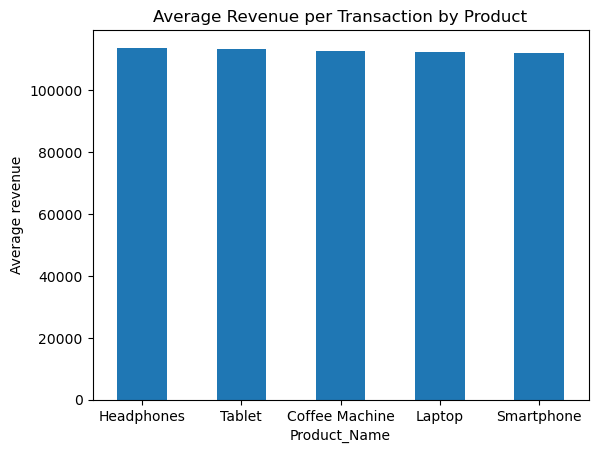

Product_Name
Headphones        113708.246049
Tablet            113106.252939
Coffee Machine    112687.785118
Laptop            112254.845832
Smartphone        112027.849339
Name: Revenue, dtype: float64

In [469]:
avg_revenue = data.groupby("Product_Name")["Revenue"].mean().sort_values(ascending = False)
avg_revenue.plot(kind = "bar" , title="Average Revenue per Transaction by Product")
plt.ylabel("Average revenue")
plt.xticks(rotation=0)
plt.show()
avg_revenue

**Finding:** Headphones has the highest average revenue per transaction (about 113,708), followed by Tablet (113,106). Smartphone is the lowest (about 112,028). The gap between highest and lowest is only about 1,680 (roughly 1.5%), so average revenue per transaction is very similar across all products.

#### Which payment method generates the highest total revenue?

In [470]:
data.groupby("Payment_Method")["Revenue"].sum().sort_values(ascending=False)

Payment_Method
Credit Card    4.353720e+09
PayPal         4.309585e+09
Cash           1.421868e+09
Name: Revenue, dtype: float64

In [471]:
# Share of total revenue by payment method (%)
(data.groupby("Payment_Method")["Revenue"].sum() / data["Revenue"].sum() * 100).round(1)

Payment_Method
Cash           14.1
Credit Card    43.2
PayPal         42.7
Name: Revenue, dtype: float64

**Finding:** Credit Card generates the highest total revenue (about 4.35 billion, 43.2% of the total), followed closely by PayPal (4.31 billion, 42.7%). Cash generates about 1.42 billion (14.1%). These shares almost match each method's share of transaction counts (43.1%, 42.7% and 14.2%), so the average revenue per transaction is similar across payment methods.

#### Which customer has generated the highest total revenue?

In [472]:
data.groupby("Customer_ID")["Revenue"].sum().sort_values(ascending= False).head(5)

Customer_ID
C2023    6.693296e+06
C643     5.659730e+06
C915     5.302313e+06
C2544    5.218796e+06
C1590    5.133351e+06
Name: Revenue, dtype: float64

**Finding:** The top 5 customers are C2023 (about 6.69 million), C643 (5.66 million), C915 (5.30 million), C2544 (5.22 million) and C1590 (5.13 million).

#### Which product has the highest total quantity sold?

In [473]:
data.groupby("Product_Name")["Quantity"].sum().sort_values(ascending= False)

Product_Name
Tablet            3889176.0
Headphones        3880130.0
Smartphone        3864315.0
Laptop            3824737.0
Coffee Machine    3805508.0
Name: Quantity, dtype: float64

**Finding:** Tablet has the highest total quantity sold (about 3.89 million units), followed by Headphones (3.88 million). Coffee Machine is lowest (about 3.81 million). The gap between the highest and lowest is only about 2.2%, so units sold are spread almost evenly across all five products.

#### Which products or payment methods have the highest number of unsuccessful transactions?

In [474]:
unsuccessful = data[data["Transaction_Status"] == "Failed"]
unsuccessful.groupby(["Product_Name","Payment_Method"]).size().sort_values(ascending=False)

Product_Name    Payment_Method
Smartphone      Credit Card       1350
Tablet          Credit Card       1346
Coffee Machine  PayPal            1304
Headphones      PayPal            1285
Laptop          Credit Card       1283
                PayPal            1282
Tablet          PayPal            1277
Coffee Machine  Credit Card       1261
Smartphone      PayPal            1260
Headphones      Credit Card       1258
                Cash               436
Smartphone      Cash               423
Tablet          Cash               422
Laptop          Cash               419
Coffee Machine  Cash               387
dtype: int64

**Finding:** Of the 14,993 failed transactions, Credit Card has the most (6,498), followed by PayPal (6,408) and Cash (2,087). By product, Tablet has the most failures (3,045) and Coffee Machine the fewest (2,952). The most failures in a single combination come from Smartphone with Credit Card (1,350). These counts mostly follow transaction volume: failures make up about 16 to 17% of each product's and each payment method's transactions, so no product or payment method fails noticeably more often than the others.

#### Compare the average transaction value across different payment methods.

In [475]:
data.groupby("Payment_Method")["Revenue"].mean().sort_values(ascending=False)

Payment_Method
Credit Card    112945.746784
PayPal         112810.464670
Cash           112019.865310
Name: Revenue, dtype: float64

**Finding:** Credit Card has the highest average transaction value (about 112,946), followed by PayPal (112,810) and Cash (112,020). The gap between the highest and lowest is under 1%, so the average transaction value is almost the same across all payment methods.

#### Compare total revenue across different transaction statuses.

In [476]:
data.groupby("Transaction_Status")["Revenue"].sum().sort_values(ascending=False)

Transaction_Status
Completed    5.003556e+09
Failed       1.710256e+09
Pending      1.690617e+09
Unknown      1.680743e+09
Name: Revenue, dtype: float64

**Finding:** Completed transactions generate the most revenue (about 5.00 billion, 49.6% of the total), followed by Failed (1.71 billion), Pending (1.69 billion) and Unknown (1.68 billion). Failed and pending transactions together account for about 3.4 billion in revenue that was not completed. The Unknown group is about 1.68 billion because its status is missing.

#### Using the Date column, identify monthly and yearly sales trends, considering only rows with valid dates.

In [477]:
valid_data = data.dropna(subset=["Transaction_Date"])

In [478]:
monthly_sales = valid_data.groupby(
    valid_data["Transaction_Date"].dt.to_period("M")
)["Revenue"].sum()

monthly_sales

Transaction_Date
2020-01    5.434166e+07
2020-02    5.119989e+07
2020-03    5.678446e+07
2020-04    4.225140e+07
2020-05    5.809627e+07
               ...     
2024-10    5.033020e+07
2024-11    5.509754e+07
2024-12    6.154712e+07
2025-01    5.465366e+07
2025-02    7.462514e+05
Freq: M, Name: Revenue, Length: 62, dtype: float64

**Finding:** Using only rows with a valid date (about 32% of transactions), monthly revenue stays fairly stable at roughly 42 to 62 million from January 2020 to January 2025, with December 2024 the highest month (about 61.5 million). February 2025 (about 0.75 million) has very little data, so it is not a real drop. There is no clear upward or downward monthly trend.

In [479]:
yearly_sales = valid_data.groupby(
    valid_data["Transaction_Date"].dt.year
)["Revenue"].sum()

yearly_sales

Transaction_Date
2020    6.158228e+08
2021    6.378043e+08
2022    6.417823e+08
2023    6.306986e+08
2024    6.409011e+08
2025    5.539991e+07
Name: Revenue, dtype: float64

**Finding:** Yearly revenue is almost flat from 2020 to 2024, between about 616 million and 642 million. 2022 is the highest year (about 642 million), and 2020 is the lowest of the full years (about 616 million). 2025 (about 55 million) covers only the first weeks of the year, so it is not a real drop. There is no clear upward or downward yearly trend.

In [480]:
print(monthly_sales.idxmax())
print(yearly_sales.idxmax())

2024-12
2022


**Finding:** December 2024 had the highest monthly sales (about 61.5 million) and 2022 had the highest yearly sales (about 641.8 million), among rows with a valid date.

## Conclusion


- **Data quality:** The raw dataset had 100,000 rows with duplicates, missing IDs, text-formatted prices, negative values, invalid dates and inconsistent spellings. After cleaning, 89,442 transactions remained.
- **Sales are evenly spread:** Total revenue is about 10.09 billion, and the average transaction is worth about 112,757. All five products have almost the same number of transactions, total revenue and average revenue per transaction (differences of about 2% or less), so no product clearly leads.
- **Payment methods:** Credit Card (43.1%) and PayPal (42.7%) are used almost equally, while Cash is far less common (14.2%). Average transaction value is almost the same across payment methods.
- **Transaction status:** Among rows with a known status, about 59.9% of transactions were completed, 20.1% failed and 20.0% were pending, so roughly one in five transactions failed. No product or payment method fails noticeably more often than the others.
- **Time trends:** Using only rows with a valid date (about 32% of the data), monthly and yearly revenue stay flat with no clear growth or decline. December 2024 is the highest month and 2022 the highest year. The very low values for February 2025 and the year 2025 reflect incomplete data, not a real drop.
- **Top customer:** Customer C2023 generated the highest revenue (about 6.69 million).

### Limitations
- A large share of prices were missing and were filled with the median, so revenue figures are partly estimates.
- About 68% of dates were invalid or missing, so time-based results cover only a subset of the data.
- Rows with a missing Customer_ID were dropped.
- Rows with an unknown status were excluded when calculating status percentages.

## Save Cleaned Data

In [481]:
# Save the cleaned dataset
data.to_csv("cleaned_transactions.csv", index=False)